# 트랜스포머 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week12/transformer/lab/transformer.ipynb)

입력 = 단어 + 위치, 블록 = 멀티헤드 어텐션 → 피드포워드 (지름길 · LayerNorm), 블록을 쌓는다.

- **파트 1**: 위치 정보 (사인 · 코사인) · 앞만 보기 마스크
- **파트 2**: 트랜스포머 블록 직접 쌓기 → 가중치 수를 $12d^2$ 와 비교
- **파트 3**: 셰익스피어 작은 GPT 학습 · 글 써 보기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 3 은 몇 분 걸린다.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. 위치 정보 · 마스크

$\text{PE}(pos, 2i) = \sin(pos / 10000^{2i/d})$, $\text{PE}(pos, 2i+1) = \cos(pos / 10000^{2i/d})$.

In [ ]:
def positional_encoding(n_pos, d):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(d)[None, :]
    angle = pos / 10000 ** (2 * (i // 2) / d)
    return None  # TODO: sin on even dims, cos on odd dims

PE = positional_encoding(64, 128)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].imshow(PE[:, :64].T, cmap="RdBu", aspect="auto"); axs[0].set_xlabel("position"); axs[0].set_ylabel("dimension")
for k in [0, 20, 40]:
    axs[1].plot(PE[:, k], label=f"dim {k}")
axs[1].set_xlabel("position"); axs[1].legend(); plt.show()

# Nearby positions have similar codes, far ones differ
print("similarity pos 10 vs 11:", round(float(PE[10] @ PE[11]), 1), "  pos 10 vs 50:", round(float(PE[10] @ PE[50]), 1))

**예상 결과**

```
similarity pos 10 vs 11: 62.1   pos 10 vs 50: 32.6
```

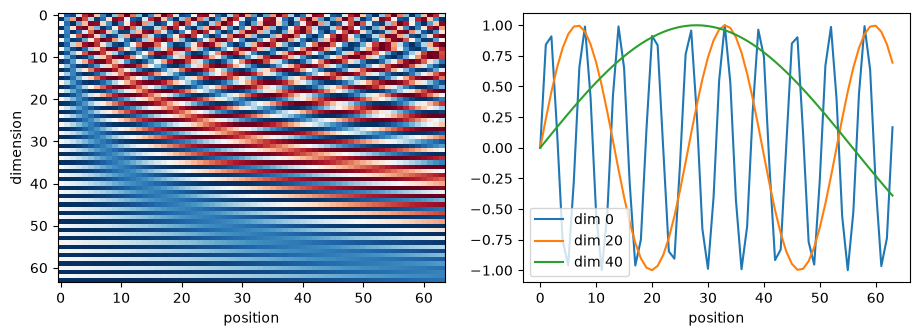

In [ ]:
def causal_mask(n):
    return None  # TODO: True above the diagonal (future words)

tokens = ["today", "lunch", "what", "eat", "?"]
mask = causal_mask(5)
print(mask.int())
scores = torch.zeros(5, 5).masked_fill(mask, float("-inf"))
print("weights:"); print(scores.softmax(-1).numpy().round(2))
print("visible cells:", int((~mask).sum()))

**예상 결과**

```
tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)
weights:
[[1.   0.   0.   0.   0.  ]
 [0.5  0.5  0.   0.   0.  ]
 [0.33 0.33 0.33 0.   0.  ]
 [0.25 0.25 0.25 0.25 0.  ]
 [0.2  0.2  0.2  0.2  0.2 ]]
visible cells: 15
```

## 파트 2. 트랜스포머 블록

정규화 먼저 (GPT 방식): $x \leftarrow x + \text{Attn}(\text{LN}(x))$, $\quad x \leftarrow x + \text{FFN}(\text{LN}(x))$.

In [ ]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mask):
        a = self.ln1(x)
        x = x + self.attn(a, a, a, attn_mask=mask, need_weights=False)[0]
        x = None  # TODO: feed-forward with a shortcut
        return x

def count_params(module):
    return sum(p.numel() for p in module.parameters())

for d in [128, 512]:
    n = count_params(Block(d, 4 if d == 128 else 8))
    print(f"d = {d}: block has {n:,} weights,  12 d^2 = {12 * d * d:,}")

**예상 결과**

```
d = 128: block has 198,272 weights,  12 d^2 = 196,608
d = 512: block has 3,152,384 weights,  12 d^2 = 3,145,728
```

## 파트 3. 작은 GPT

폭 128, 4층, 머리 4. 길이 64 조각에서 매 칸의 다음 글자를 맞힌다 (11주차와 같은 데이터).

In [ ]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/shakespeare.txt"):
    import urllib.request; urllib.request.urlretrieve(url, "data/shakespeare.txt")
text = open("data/shakespeare.txt").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text])
cut = int(len(data) * 0.9)
train_data, val_data = data[:cut], data[cut:]
print(len(text), "characters,", len(chars), "distinct")

**예상 결과**

```
1115394 characters, 65 distinct
```

In [ ]:
class GPT(nn.Module):
    def __init__(self, vocab, d=128, layers=4, heads=4, seq=64):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(seq, d)                  # learned position vectors (like GPT)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(layers)])
        self.ln = nn.LayerNorm(d)
        self.out = nn.Linear(d, vocab)

    def forward(self, x):
        T = x.shape[1]
        h = None  # TODO: word vector + position vector
        mask = causal_mask(T)
        for block in self.blocks:
            h = block(h, mask)
        return self.out(self.ln(h))

def get_batch(data, seq=64, batch=64, gen=None):
    ix = torch.randint(0, len(data) - seq - 1, (batch,), generator=gen)
    x = torch.stack([data[i:i + seq] for i in ix])
    y = torch.stack([data[i + 1:i + seq + 1] for i in ix])
    return x, y

def train_gpt(train_data, vocab, steps=1000):
    torch.manual_seed(0)
    model = GPT(vocab); opt = torch.optim.Adam(model.parameters(), 1e-3); gen = torch.Generator().manual_seed(0)
    losses = []
    for step in range(steps):
        x, y = get_batch(train_data, gen=gen)
        loss = nn.functional.cross_entropy(model(x).reshape(-1, vocab), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        losses.append(loss.item())
        if step % 200 == 0:
            print(f"step {step}: loss {loss.item():.2f}")
    return model, losses

model, losses = train_gpt(train_data, len(chars))
print("weights:", f"{count_params(model):,}")
model.eval()
x, y = get_batch(val_data, batch=200, gen=torch.Generator().manual_seed(1))
with torch.no_grad():
    print("validation loss:", round(nn.functional.cross_entropy(model(x).reshape(-1, len(chars)), y.reshape(-1)).item(), 3))
plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.show()

**예상 결과**

```
step 0: loss 4.37
step 200: loss 2.17
step 400: loss 1.88
step 600: loss 1.69
step 800: loss 1.55
weights: 818,241
validation loss: 1.704
```

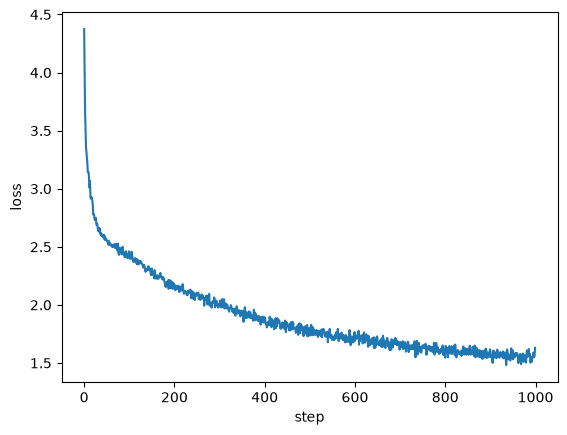

In [ ]:
def generate(model, start, stoi, chars, n=300, temperature=0.8, seq=64, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor([[stoi[c] for c in start]])
    with torch.no_grad():
        for _ in range(n):
            logits = model(x[:, -seq:])                  # only the last 64 characters fit
            p = torch.softmax(logits[0, -1] / temperature, dim=0)
            x = torch.cat([x, torch.multinomial(p, 1, generator=g)[None]], 1)
    return "".join(chars[i] for i in x[0].tolist())

print(generate(model, "ROMEO:", stoi, chars, 300))

**예상 결과**

```
ROMEO:
Threat this wiselt indeed means your wiltle feel consendend now
This hear this being steeds him. That's yet yith
That cost all forrong-day firster'd with to all which
Eith, been I no sufficed never and to fail in
Fillompon not say time of livel of will bind.

GLOUCESTER:
Some your pone so rathers a
```

**확인 질문**
1. 파트 1 에서 위치 10 과 11 의 위치 벡터는 비슷하고 10 과 50 은 다르다. 이것이 왜 쓸모 있을까?
2. 파트 2 에서 실제 가중치 수가 $12d^2$ 보다 조금 많은 이유는?
3. 파트 3 의 `generate` 에서 `x[:, -seq:]` 로 마지막 64 글자만 넣는 이유는?
4. (도전) `GPT` 에서 위치 벡터를 빼고 다시 학습하면 검증 손실은? (슬라이드: 1.61 → 1.68, 2,000걸음)

데이터 출처: Tiny Shakespeare, Andrej Karpathy char-rnn (2015).